# False color fires
- Author: Michaela Dennis
- [Github repository](https://github.com/michaeladennis/eds220-hwk4)

## About
### Notebook purpose
This purpose of this notebook is to create a false color image of the Eaton and Palisades Fires using remote sensing data.
### Highlights: List of highlights of analysis (3 or 4 highlights). What do you consider to be the most important aspects of this coding exercise?
- CRS manipulation/checks
- restoring geometry features when they get lost in the data
- understanding and manipulating missing values to visualize data despite presence of NAs

### About the data
This notebook contains three datasets, Landsat imagery, the Eaton fire boundary, and the Palisades fire boundary. The landsat data comes from the Landsat 8 Satellite, from the [Microsoft Planetary Computer data catalog](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2), and shows an image of Los Angeles relative to the area surrounding the Eaton and Palisades fire perimeters. Both of the Eaton and Palisades fire boundaries come form the [LA city ArcGIS](https://geohub.lacity.org/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about). Both are delineations of the areas where the two fires occurred. 

### References


## Import packages and data

In [34]:
import os 
import numpy as np
import matplotlib.pyplot as plt

import geopandas as gpd
import xarray as xr    
import rioxarray as rioxr

In [35]:
# fire boundaries

eaton = gpd.read_file('/Users/michaela/github/eds220/eds220-hwk4/data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp')
palisades = gpd.read_file('/Users/michaela/github/eds220/eds220-hwk4/data/Palisades_Perimieter_20250121/Palisades_Perimieter_20250121.shp')

### Fire perimeter data exploration

In [36]:
# Check out the CRS
print('Eaton boundary CRS: ', eaton.crs)
print('Palisades boundary CRS: ', palisades.crs)

Eaton boundary CRS:  EPSG:4269
Palisades boundary CRS:  EPSG:4269


In [37]:
# Check out the geometries
print('Eaton boundary geometry: ', eaton.geometry)
print('Palisades boundary geometry: ', palisades.geometry)

Eaton boundary geometry:  0    MULTIPOLYGON (((-118.10093 34.16680, -118.1008...
Name: geometry, dtype: geometry
Palisades boundary geometry:  0    MULTIPOLYGON (((-118.51974 34.02996, -118.5198...
Name: geometry, dtype: geometry


In [38]:
eaton.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [39]:
palisades.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


In [40]:
eaton.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    1 non-null      int64   
 1   YEAR_       1 non-null      int64   
 2   STATE       1 non-null      object  
 3   AGENCY      1 non-null      object  
 4   UNIT_ID     1 non-null      object  
 5   FIRE_NAME   1 non-null      object  
 6   type        1 non-null      object  
 7   INC_NUM     1 non-null      object  
 8   IRWINID     1 non-null      object  
 9   ALARM_DATE  1 non-null      object  
 10  CONT_DATE   1 non-null      object  
 11  CAUSE       1 non-null      int64   
 12  C_METHOD    1 non-null      int64   
 13  OBJECTIVE   1 non-null      int64   
 14  GIS_ACRES   1 non-null      float64 
 15  COMMENTS    0 non-null      object  
 16  COMPLEX_NA  0 non-null      object  
 17  COMPLEX_ID  0 non-null      object  
 18  FIRE_NUM    0 non-null      object  
 19  Glob

In [41]:
palisades.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 24 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    1 non-null      int64   
 1   YEAR_       1 non-null      int64   
 2   STATE       1 non-null      object  
 3   AGENCY      1 non-null      object  
 4   UNIT_ID     1 non-null      object  
 5   FIRE_NAME   1 non-null      object  
 6   type        1 non-null      object  
 7   INC_NUM     1 non-null      object  
 8   IRWINID     1 non-null      object  
 9   ALARM_DATE  1 non-null      object  
 10  CONT_DATE   1 non-null      object  
 11  CAUSE       1 non-null      int64   
 12  C_METHOD    1 non-null      int64   
 13  OBJECTIVE   1 non-null      int64   
 14  GIS_ACRES   1 non-null      float64 
 15  COMMENTS    0 non-null      object  
 16  COMPLEX_NA  0 non-null      object  
 17  COMPLEX_ID  0 non-null      object  
 18  FIRE_NUM    0 non-null      object  
 19  Glob

In [ ]:
# Use .is_geographic and .is_projected to see what type the CRSs are for both the Eaton and Palisades fires 

print('(Eaton) Is geogrpahic? ', eaton.crs.is_geographic)
print('(Palisades) Is geogrpahic? ', palisades.crs.is_geographic)

print('(Eaton) Is projected: ', eaton.crs.is_projected)
print('(Palisades) Is projected: ', palisades.crs.is_projected)

(Eaton) Is geogrpahic?  True
(Palisades) Is geogrpahic?  True
(Eaton) Is projected:  False
(Palisades) Is projected:  False


#### Boundaries summary
The Eaton and the Palisades boundaries are both multipolygon geometries (vectors) with the same CRS: EPSG:4269. EPSG:4269 is a geographic CRS.

### NetCDF data exploration

In [43]:
# Import landsat file
fp = os.path.join('/Users/michaela/github/eds220/eds220-hwk4/data/landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp)

In [44]:
landsat.dtypes

Frozen({'red': dtype('float32'), 'green': dtype('float32'), 'blue': dtype('float32'), 'nir08': dtype('float32'), 'swir22': dtype('float32'), 'spatial_ref': dtype('int64')})

In [ ]:
# Check to see if landsat has a CRS
print('Landsat CRS: ', landsat.rio.crs)

Landsat CRS:  None


#### Landsat summary
The variables in this data are each of the landsat bands, red, green, blue, nir, swir. The dimensions are latitude and longitude stored as x and y. There is currently no CRS because the object is not yet spatial!

### Restoring geospatial information

In [ ]:
# Check where the geospatial data is hidden in the landsat data
landsat['spatial_ref'].crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [ ]:
# Update CRS from the hidden geospatial info
crs = landsat.spatial_ref.crs_wkt
landsat = landsat.rio.write_crs(crs)


In [49]:
# Check the updated CRS
print('Updated landsat CRS: ', landsat.rio.crs)

Updated landsat CRS:  EPSG:32611


### True color image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


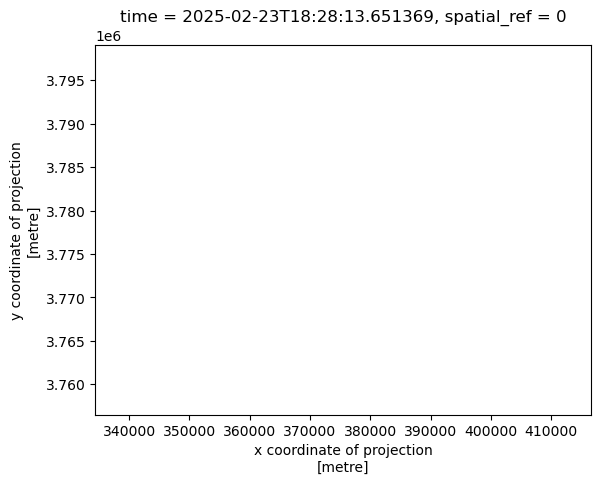

In [ ]:
# Index the RGB bands to plot the image
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


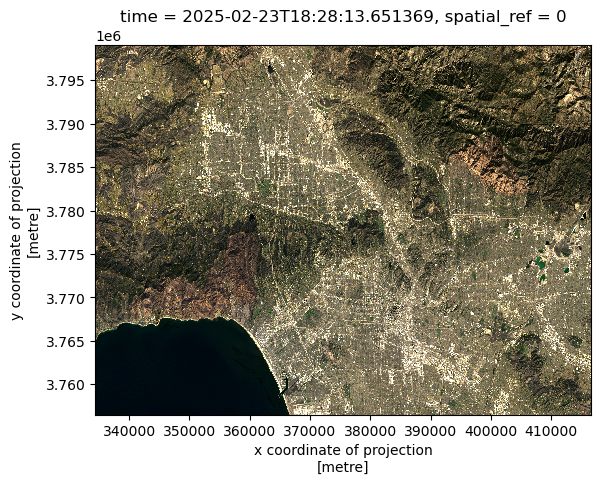

In [ ]:
# Use the robust parameter so we can see the image properly
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)

In [ ]:
# Check the NAs from the color bands
np.isnan(landsat[['red', 'green', 'blue']].to_dataarray()).sum()

<xarray.DataArray ()> Size: 8B
array(110)
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0

In [ ]:
# Fill the NA values with 0s so we can properly plot with no warnings
landsat[['red', 'green', 'blue']].to_dataarray().fillna(0)

<xarray.DataArray (variable: 3, y: 1418, x: 2742)> Size: 47MB
array([[[10242.,  9886., 10142., ...,  8478.,  9179.,  9088.],
        [10338., 10263., 10255., ...,  8299.,  8645.,  8662.],
        [10312., 10153., 10300., ...,  9382.,  9123.,  8997.],
        ...,
        [ 7339.,  7334.,  7322., ..., 11020., 10743., 10067.],
        [ 7345.,  7336.,  7336., ..., 10899., 10877., 11075.],
        [ 7336.,  7330.,  7345., ..., 10327., 10188.,  9967.]],

       [[ 9930.,  9687.,  9894., ...,  8532.,  9138.,  8904.],
        [10046.,  9968.,  9925., ...,  8447.,  8679.,  8673.],
        [10026.,  9851.,  9944., ...,  9220.,  9069.,  8959.],
        ...,
        [ 7687.,  7699.,  7704., ..., 10526., 10417.,  9908.],
        [ 7686.,  7682.,  7685., ..., 10301., 10200., 10384.],
        [ 7699.,  7685.,  7686., ..., 10176.,  9984.,  9662.]],

       [[ 9290.,  9183.,  9344., ...,  8030.,  8352.,  8333.],
        [ 9374.,  9383.,  9338., ...,  7913.,  8110.,  8154.],
        [ 9369.,  9326.,  9367., ...,  8642.,  8434.,  8304.],
        ...,
        [ 7924.,  7921.,  7921., ...,  9976.,  9652.,  9260.],
        [ 7916.,  7910.,  7921., ...,  9487.,  9525.,  9803.],
        [ 7917.,  7904.,  7913., ...,  9624.,  9490.,  9187.]]],
      dtype=float32)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
  * variable     (variable) object 24B 'red' 'green' 'blue'

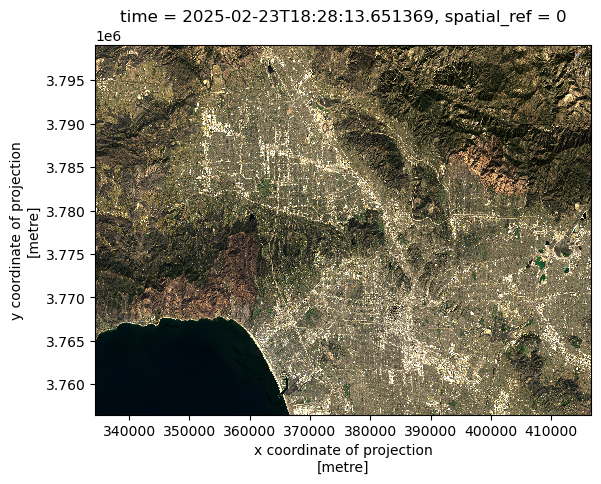

In [ ]:
# Final plot for RGB with NAs converted to 0s
landsat[['red', 'green', 'blue']].to_dataarray().fillna(0).plot.imshow(robust=True)


#### Differences between the outputs before and after correcting for NA values
Before correcting for NAs we get the warning "invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)". As we plot, each of the cell values is taken as a number and plotted as an RGB value. When we have NAs in our dataset the code is not able to properly plot like we want it to. The second output has no warning and prints a clean image because all of the missing values have been converted to 0s, which will alow them to go through the necessary math operations to be plotted.


### False color image

In [ ]:
# index the shortwave infrared (swir22), near-infrared, and red variables (in that order) for a false color image
landsat_false = landsat[['swir22', 'nir08', 'red']].to_dataarray()

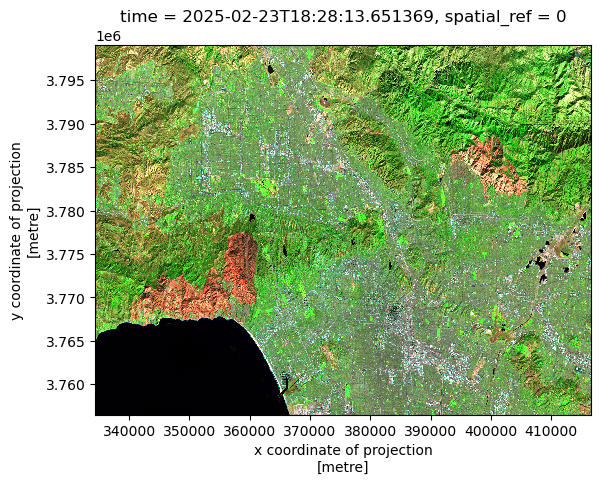

In [56]:
landsat_false.plot.imshow(robust=True)

### Map

In [ ]:
# Match the crs and make sure it matches
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)
assert eaton.crs == palisades.crs == landsat.rio.crs

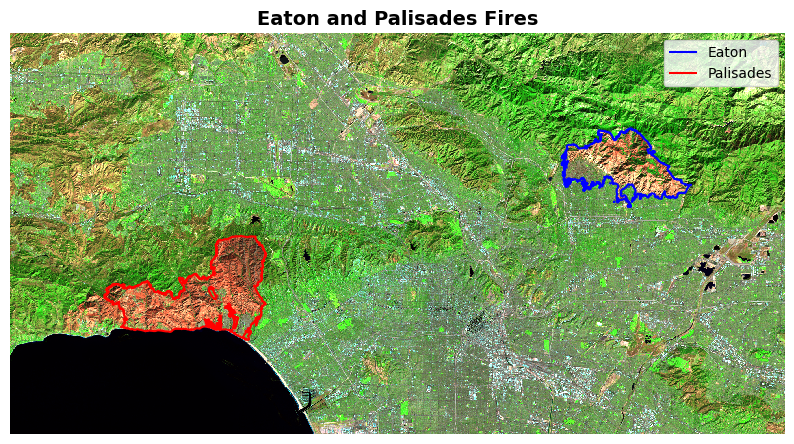

In [ ]:
# Plot all of the objects together with proper labeling. 
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('off')

# Landsat false image
landsat[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust=True, ax=ax)

eaton.boundary.plot(ax=ax, edgecolor= "blue", label="Eaton"
                                    )

palisades.boundary.plot(ax=ax, edgecolor= "red", label="Palisades"
                                    )

plt.legend()

ax.set_title("Eaton and Palisades Fires", fontsize=14, fontweight='bold')



plt.show()